# Test de l'espace digit : contient-il le style ?

Le domaine digit devrait ne contenir que le chiffre (one-hot) et l'angle (cos, sin). Une image traduite en digit puis
reconvertie en image devrait donc donner un chiffre « standardisé », sans le style d'écriture.

**Hypothèse** : la loss de cycle image → GW → digit → GW → image renvoie dans le GW le vecteur digit **continu** prédit
(pas un one-hot exact) et elle est différentiable. Le modèle a donc intérêt à cacher le style dans les petits écarts de
ce vecteur (0.97 au lieu de 1, 0.02 au lieu de 0...) pour mieux reconstruire l'image. Avec 12 dimensions contre 10 pour
le GW, il en a largement la place.

1. Image → digit : reconnaissance, et « propreté » du vecteur digit
2. Image → digit → image, avec le vecteur digit brut ou nettoyé (one-hot exact + angle de norme 1)
3. Échange des écarts : le style d'une image passe-t-il par les écarts de son vecteur digit ?
4. Sonde : quelle part du latent VAE de l'image (style compris) peut-on retrouver à partir du vecteur digit ?
5. Cycle digit → image → digit

In [ ]:
import torch
import torch.nn.functional as F
from torch import nn

from numb_project.constants import BASE, DEVICE, GW_CHECKPOINT_FOLDER
from numb_project.notebook_utils import *

torch.set_grad_enabled(False)  # sauf pour la sonde (section 4)

gw = load_global_workspace(f"{GW_CHECKPOINT_FOLDER}/rotation_all.ckpt")

images, labels = mnist_batch(1000)
angles = random_angles(len(images))
rotated = rotate_images(images, angles)


def image_to_digit(x: torch.Tensor) -> torch.Tensor:
    return from_gw(gw, "digit", image_to_gw(gw, x))


def digit_to_image(d: torch.Tensor) -> torch.Tensor:
    return gw_to_image(gw, to_gw(gw, "digit", d))

# clean_digit (numb_project/utils.py) : one-hot exact du chiffre lu, (cos, sin) de norme 1


digits = image_to_digit(rotated)

/home/lucas/.cache/pypoetry/virtualenvs/gwnumb-bz7TIj5U-py3.11/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'rotation_mods' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['rotation_mods'])`.


## 1. Image → digit

Reconnaissance du chiffre et de l'angle, puis écart du vecteur prédit à sa version propre. Un vecteur digit « honnête »
serait proche d'un one-hot avec un (cos, sin) de norme 1.

image -> digit : précision chiffre =  89.5%, erreur d'angle moyenne =  12.8° (médiane   8.6°)
valeur du chiffre reconnu  : moyenne 0.869, écart-type 0.229
autres composantes         : |valeur| moyenne 0.068
norme de (cos, sin)        : moyenne 0.954, écart-type 0.109
norme de l'écart au propre : moyenne 0.357

quelques vecteurs digit prédits (10 composantes one-hot | cos, sin) :
  chiffre 1 :  0.01  1.10 -0.06 -0.03 -0.03 -0.11  0.01  0.02 -0.02 -0.07 | -0.50  0.72
  chiffre 7 :  0.02  0.10  0.18 -0.02 -0.05  0.03 -0.04  1.15 -0.04 -0.10 | -0.93 -0.24
  chiffre 7 :  0.05 -0.04 -0.07  0.00  0.01  0.12  0.06  1.13 -0.03 -0.06 |  1.03 -0.03
  chiffre 5 : -0.09 -0.05  0.01 -0.08 -0.14  0.81  0.29 -0.03  0.16  0.16 |  0.91 -0.36


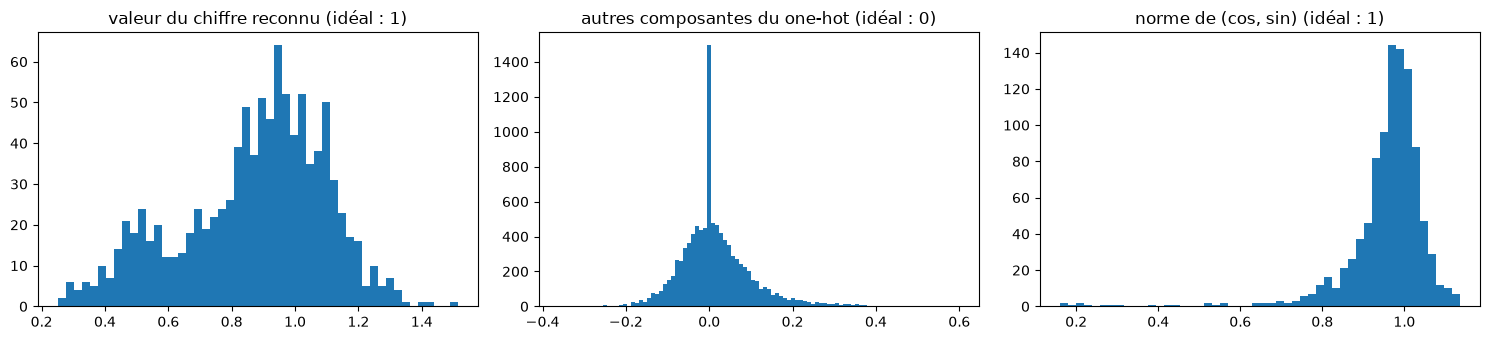

In [ ]:
print("image -> digit :", format_recognition(digits, labels, angles))

one_hot, cos_sin = digits[:, :BASE], digits[:, BASE:]
top = one_hot.max(dim=-1).values
others = one_hot.scatter(1, one_hot.argmax(-1, keepdim=True), 0.0)
norm = cos_sin.norm(dim=-1)
residual = digits - clean_digit(digits)
print(f"valeur du chiffre reconnu  : moyenne {top.mean():.3f}, écart-type {top.std():.3f}")
print(f"autres composantes         : |valeur| moyenne {others.abs().sum(-1).mean() / (BASE - 1):.3f}")
print(f"norme de (cos, sin)        : moyenne {norm.mean():.3f}, écart-type {norm.std():.3f}")
print(f"norme de l'écart au propre : moyenne {residual.norm(dim=-1).mean():.3f}")

print("\nquelques vecteurs digit prédits (10 composantes one-hot | cos, sin) :")
for d, label in zip(digits[:4], labels[:4]):
    print(f"  chiffre {label.item()} :", " ".join(f"{v:5.2f}" for v in d[:BASE].tolist()), "|",
          " ".join(f"{v:5.2f}" for v in d[BASE:].tolist()))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].hist(top.cpu(), bins=50)
axes[0].set_title("valeur du chiffre reconnu (idéal : 1)")
axes[1].hist(others.flatten().cpu(), bins=100)
axes[1].set_title("autres composantes du one-hot (idéal : 0)")
axes[2].hist(norm.cpu(), bins=50)
axes[2].set_title("norme de (cos, sin) (idéal : 1)")
plt.tight_layout()
plt.show()

## 2. Image → digit → image : vecteur brut ou nettoyé

Si le style passe par les écarts du vecteur digit, l'image obtenue avec le vecteur brut garde le style, et celle obtenue
avec le vecteur nettoyé est standardisée. Le demi-cycle image → GW → image sert de référence.

MSE demi-cycle GW      vs original : 0.0256
MSE via digit brut     vs original : 0.0271
MSE via digit nettoyé  vs original : 0.0544


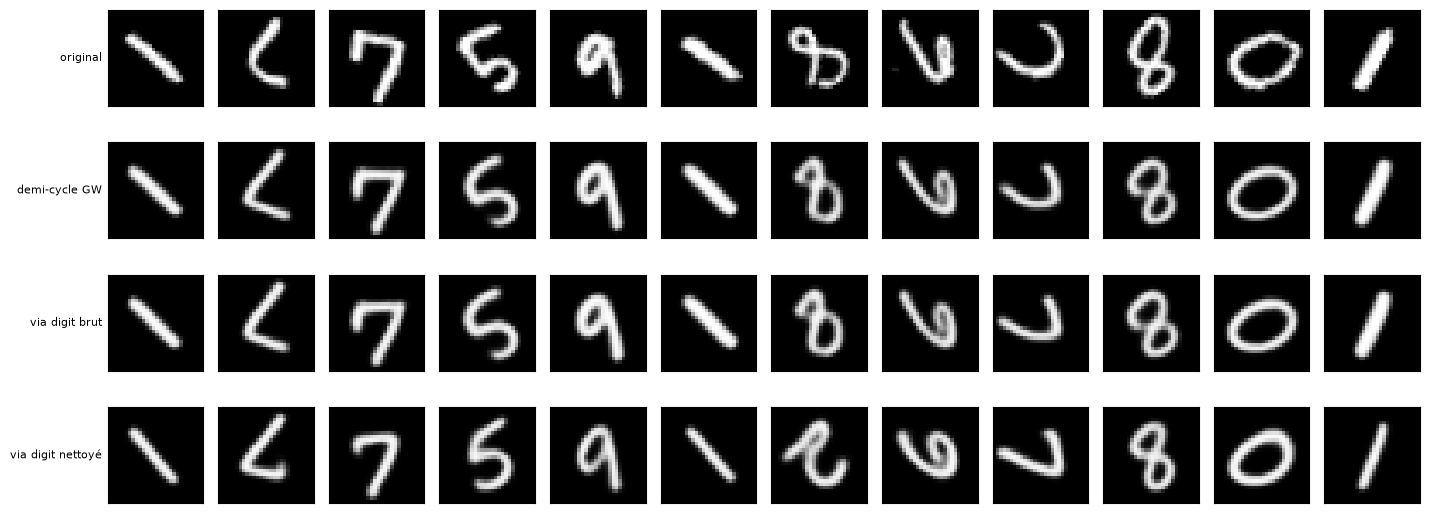

In [ ]:
via_gw = gw_to_image(gw, image_to_gw(gw, rotated))
via_digit = digit_to_image(digits)
via_clean = digit_to_image(clean_digit(digits))
for name, x in [("demi-cycle GW", via_gw), ("via digit brut", via_digit), ("via digit nettoyé", via_clean)]:
    print(f"MSE {name:<18} vs original : {F.mse_loss(x, rotated):.4f}")

show_rows([
    ("original", rotated),
    ("demi-cycle GW", via_gw),
    ("via digit brut", via_digit),
    ("via digit nettoyé", via_clean),
], n_show=12)

## 3. Échange des écarts entre deux images du même chiffre

Pour deux images A et B du même chiffre, on prend la partie propre du vecteur digit de A (chiffre + angle) et on lui
ajoute les écarts du vecteur de B. Si l'image obtenue prend le style de B (épaisseur, inclinaison, forme), c'est que les
écarts du vecteur digit transportent le style.

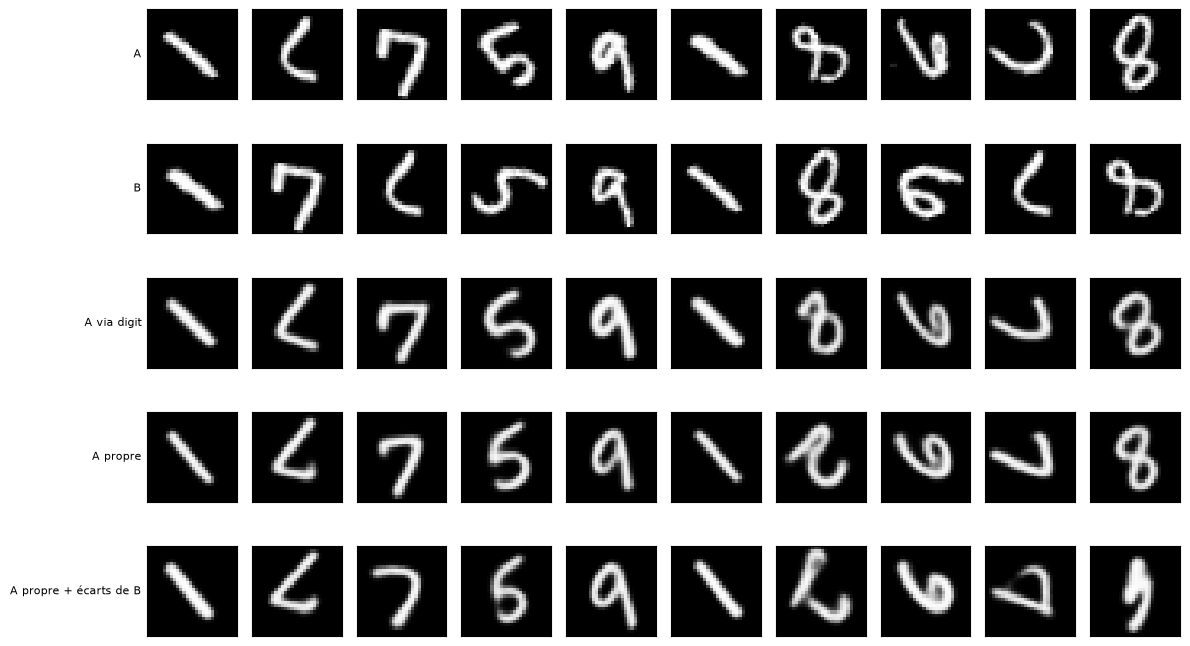

In [ ]:
n_pairs = 10
a_idx, b_idx = [], []
for i in range(len(labels)):
    same = (labels == labels[i]).nonzero().flatten()
    same = same[same != i]
    a_idx.append(i)
    b_idx.append(same[0].item())
    if len(a_idx) == n_pairs:
        break
a_idx, b_idx = torch.tensor(a_idx), torch.tensor(b_idx)

d_a, d_b = digits[a_idx], digits[b_idx]
mixed = clean_digit(d_a) + (d_b - clean_digit(d_b))
show_rows([
    ("A", rotated[a_idx]),
    ("B", rotated[b_idx]),
    ("A via digit", digit_to_image(d_a)),
    ("A propre", digit_to_image(clean_digit(d_a))),
    ("A propre + écarts de B", digit_to_image(mixed)),
], n_show=n_pairs)

## 4. Sonde : le vecteur digit permet-il de retrouver l'image ?

On entraîne un petit MLP à prédire le latent du VAE de l'image (20D, qui contient chiffre, angle **et** style), à partir de :
- l'état GW (borne haute : ce que le GW sait de l'image) ;
- le vecteur digit brut ;
- le vecteur digit nettoyé (chiffre + angle seulement).

Le R² mesure la part de la variance du latent expliquée. Si le vecteur brut fait nettement mieux que le vecteur nettoyé,
le surplus vient du style caché dans les écarts. Entraînement sur des images du train set, évaluation sur le test set.

In [ ]:
def in_chunks(fn, x: torch.Tensor, size: int = 2000) -> torch.Tensor:
    return torch.cat([fn(x[i:i + size]) for i in range(0, len(x), size)])


def probe_r2(features_train, targets_train, features_test, targets_test, steps: int = 3000) -> float:
    """R² sur le test d'un MLP entraîné à prédire `targets` à partir de `features`."""
    torch.manual_seed(0)
    probe = nn.Sequential(nn.Linear(features_train.shape[1], 256), nn.ReLU(),
                          nn.Linear(256, 256), nn.ReLU(),
                          nn.Linear(256, targets_train.shape[1])).to(DEVICE)
    optimizer = torch.optim.Adam(probe.parameters(), lr=1e-3)
    with torch.enable_grad():
        for _ in range(steps):
            idx = torch.randint(0, len(features_train), (512,), device=DEVICE)
            loss = F.mse_loss(probe(features_train[idx]), targets_train[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    mse = F.mse_loss(probe(features_test), targets_test)
    return (1 - mse / targets_test.var(dim=0).mean()).item()


train_images, _ = mnist_batch(20000, train=True, seed=1)
train_images = rotate_images(train_images, random_angles(len(train_images), seed=1))
image_mod = gw.gw_mod.domain_mods["image"]
spaces = {
    "état GW": lambda x: image_to_gw(gw, x),
    "digit brut": image_to_digit,
    "digit nettoyé": lambda x: clean_digit(image_to_digit(x)),
}
vae_train, vae_test = in_chunks(image_mod.encode, train_images), image_mod.encode(rotated)
for name, fn in spaces.items():
    r2 = probe_r2(in_chunks(fn, train_images), vae_train, fn(rotated), vae_test)
    print(f"R² du latent VAE prédit depuis {name:<14}: {r2:.3f}")

R² du latent VAE prédit depuis état GW       : 0.788


R² du latent VAE prédit depuis digit brut    : 0.758


R² du latent VAE prédit depuis digit nettoyé : 0.451


## 5. Cycle digit → image → digit

On part de vrais vecteurs digit propres (chiffre + angle aléatoire), on génère l'image puis on la relit. Ici, aucune
information de style n'existe au départ : l'image générée est forcément un chiffre « standardisé ».

digit -> image -> digit : précision chiffre = 100.0%, erreur d'angle moyenne =   2.8° (médiane   2.6°)
MSE vecteur digit après cycle : 0.0013
MSE vecteur digit pour image -> digit (référence) : 0.0264


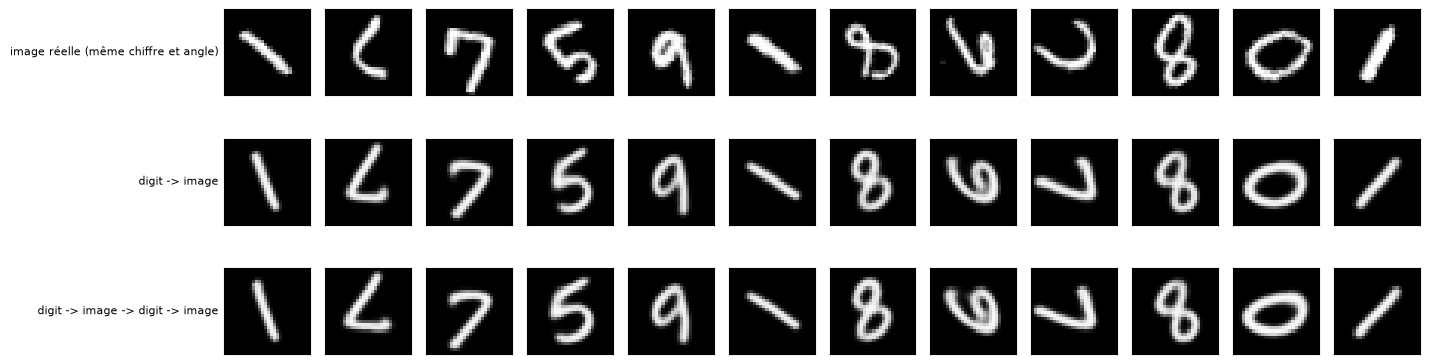

In [ ]:
true_digits = digit_vector(labels, angles)
generated = digit_to_image(true_digits)
cycled = image_to_digit(generated)
print("digit -> image -> digit :", format_recognition(cycled, labels, angles))
print(f"MSE vecteur digit après cycle : {F.mse_loss(cycled, true_digits):.4f}")
print(f"MSE vecteur digit pour image -> digit (référence) : {F.mse_loss(digits, true_digits):.4f}")

show_rows([
    ("image réelle (même chiffre et angle)", rotated),
    ("digit -> image", generated),
    ("digit -> image -> digit -> image", digit_to_image(cycled)),
], n_show=12)

## Conclusion

Résultats obtenus avec `rotation_all.ckpt` :

- **Image → digit** : 86 % de chiffres reconnus, 14° d'erreur d'angle moyenne. Le vecteur prédit est loin d'un one-hot
  propre : la composante du chiffre reconnu vaut 0.84 ± 0.24, et l'écart au vecteur propre a une norme moyenne de 0.4.
- **Image → digit → image** : avec le vecteur brut, l'image garde le style (MSE 0.030, presque comme le demi-cycle GW à
  0.028). Avec le vecteur nettoyé, le chiffre est standardisé (MSE 0.054).
- **Échange des écarts** : ajouter les écarts du vecteur de B à la partie propre de A change nettement l'image ; le
  style passe donc par ces écarts.
- **Sonde** : le latent VAE de l'image se retrouve presque aussi bien depuis le vecteur digit brut (R² 0.75) que depuis
  l'état GW (0.77), contre 0.44 depuis le vecteur nettoyé. Le vecteur digit est donc presque une copie du GW.
- **Digit → image → digit** : quasi parfait (100 %, 2.3°). Partant d'un vecteur propre, l'image générée est bien standardisée.

**Cause** : la loss de cycle image → GW → digit → GW → image. Elle demande de reconstruire l'image originale, style
compris, en passant par le domaine digit, ce qui est impossible sans cacher le style dans le vecteur digit continu.
Le modèle le fait, avec 12 dimensions disponibles pour un GW de 10.

**Conséquence pour les rotations** : les voies « digit » et « GW via digit » ne sont pas vraiment symboliques avec ce
modèle, puisqu'elles transportent aussi le style.